# Sistema de clasificación de imágenes: perros y gatos

El objetivo de este proyecto es construir una red neuronal capaz de clasificar imágenes de perros y gatos.

Utilizaremos EfficientNetB0 para extraer características de las imágenes y realizar la clasificación mediante una red neuronal.

In [1]:
import os
import glob
import shutil
import zipfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

np.random.seed(42)
tf.random.set_seed(42)

I0000 00:00:1792658371.037939   16975 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792658371.040129   16975 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792658372.125364   16975 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792658376.152272   16975 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [2]:
#Descargar y localizar el dataset
zip_path = Path("dogs-vs-cats.zip")
extract_path = Path("dogs_vs_cats")

if not zip_path.exists():
    url = "https://storage.googleapis.com/datascience-materials/dogs-vs-cats.zip"
    urllib.request.urlretrieve(url, zip_path)

if not extract_path.exists():
    extract_path.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

image_files = list(extract_path.rglob("*.jpg"))

print("Total de imágenes encontradas:", len(image_files))
print("Primeras imágenes:", [f.name for f in image_files[:5]])

Total de imágenes encontradas: 50000
Primeras imágenes: ['cat.11800.jpg', 'dog.2174.jpg', 'dog.9676.jpg', 'dog.558.jpg', 'dog.11702.jpg']


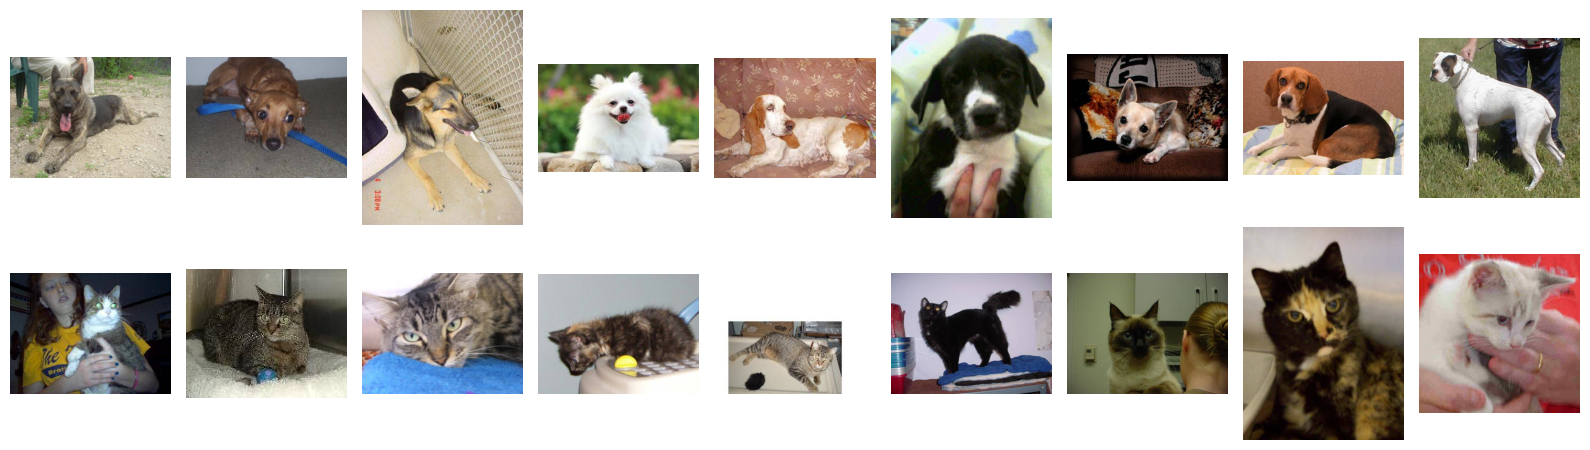

In [3]:
#Visualizar nueve perros y nueve gato
cats = [f for f in image_files if f.name.lower().startswith("cat.")]
dogs = [f for f in image_files if f.name.lower().startswith("dog.")]

fig, axes = plt.subplots(2, 9, figsize=(16, 5))

for i, file in enumerate(dogs[:9]):
    axes[0, i].imshow(load_img(file))
    axes[0, i].axis("off")

for i, file in enumerate(cats[:9]):
    axes[1, i].imshow(load_img(file))
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Perros")
axes[1, 0].set_ylabel("Gatos")

plt.tight_layout()
plt.show()

In [4]:
#Preparar las carpetas
#El generador necesita una carpeta por clase. Como el dataset original puede contener todas las imágenes juntas, las dividiremos en entrenamiento y test.
from sklearn.model_selection import train_test_split

base_dir = Path("dataset")
train_dir = base_dir / "train"
test_dir = base_dir / "test"

for split_dir in [train_dir, test_dir]:
    for category in ["cat", "dog"]:
        (split_dir / category).mkdir(parents=True, exist_ok=True)

if not any(train_dir.rglob("*.jpg")) and not any(test_dir.rglob("*.jpg")):
    train_files, test_files = train_test_split(
        image_files,
        test_size=0.2,
        random_state=42,
        stratify=[
            "cat" if f.name.lower().startswith("cat.") else "dog"
            for f in image_files
        ]
    )

    for file in train_files:
        category = "cat" if file.name.lower().startswith("cat.") else "dog"
        shutil.copy2(file, train_dir / category / file.name)

    for file in test_files:
        category = "cat" if file.name.lower().startswith("cat.") else "dog"
        shutil.copy2(file, test_dir / category / file.name)

print("Imágenes de entrenamiento:", len(list(train_dir.rglob("*.jpg"))))
print("Imágenes de test:", len(list(test_dir.rglob("*.jpg"))))

Imágenes de entrenamiento: 20019
Imágenes de test: 4981


In [5]:
#Crear los generadores
#Usaremos imágenes de 224 × 224 píxeles para que coincidan con la arquitectura indicada en el enunciado.
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

trdata = train_datagen.flow_from_directory(
    str(train_dir),
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=True
)

tsdata = test_datagen.flow_from_directory(
    str(test_dir),
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

print("Clases:", trdata.class_indices)

Found 20019 images belonging to 2 classes.
Found 4981 images belonging to 2 classes.
Clases: {'cat': 0, 'dog': 1}


In [6]:
#Construir la red neuronal
model = Sequential()

model.add(EfficientNetB0(
    include_top=False,
    weights=None,
    input_shape=(224, 224, 3)
))

model.add(GlobalAveragePooling2D())
model.add(Dense(units=128, activation="relu"))
model.add(Dense(units=2, activation="softmax"))

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

E0000 00:00:1792658381.457637   16975 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 4,171,774 (15.91 MB)

 Non-trainable params: 42,023 (164.16 KB)

### Limpieza de imágenes dañadas

Durante la preparación del dataset, algunas imágenes pueden estar dañadas o no tener un formato válido. Esto provoca un error al intentar cargarlas durante el entrenamiento.

Para solucionarlo, revisamos los archivos de las carpetas de entrenamiento y prueba utilizando la librería PIL. Comprobamos que cada archivo pueda abrirse y verificamos su integridad.

Los archivos que no se pueden leer correctamente se identifican y eliminan para evitar errores durante el entrenamiento de la red neuronal.

Finalmente, volvemos a crear los generadores `trdata` y `tsdata` para continuar con el entrenamiento de EfficientNetB0.

In [7]:
from PIL import Image
from pathlib import Path

carpetas = [train_dir, test_dir]
imagenes_danadas = []

for carpeta in carpetas:
    for archivo in carpeta.rglob("*"):
        if archivo.is_file():
            try:
                with Image.open(archivo) as img:
                    img.verify()
            except Exception:
                imagenes_danadas.append(archivo)

print("Imágenes dañadas:", len(imagenes_danadas))

for archivo in imagenes_danadas[:20]:
    print(archivo)

Imágenes dañadas: 0


In [8]:
for archivo in imagenes_danadas:
    archivo.unlink()

print("Archivos dañados eliminados.")

Archivos dañados eliminados.


In [9]:
#Volver a crear los generadores
trdata = train_datagen.flow_from_directory(
    str(train_dir),
    target_size=(224, 224),
    batch_size=8,
    class_mode="categorical",
    shuffle=True
)

tsdata = test_datagen.flow_from_directory(
    str(test_dir),
    target_size=(224, 224),
    batch_size=8,
    class_mode="categorical",
    shuffle=False
)

Found 20019 images belonging to 2 classes.
Found 4981 images belonging to 2 classes.


In [11]:
#Entrenar y optimizar el modelo
os.makedirs("models", exist_ok=True)

checkpoint = ModelCheckpoint(
    "models/best_dogs_cats.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    trdata,
    validation_data=tsdata,
    steps_per_epoch=100,
    validation_steps=20,
    epochs=2,
    callbacks=[checkpoint, early_stop],
    verbose=1
)

Epoch 1/2
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6062 - loss: 0.6622
Epoch 1: val_accuracy improved from None to 0.72500, saving model to models/best_dogs_cats.keras

Epoch 1: finished saving model to models/best_dogs_cats.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.6062 - loss: 0.6622 - val_accuracy: 0.7250 - val_loss: 0.5962
Epoch 2/2
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6237 - loss: 0.6363
Epoch 2: val_accuracy improved from 0.72500 to 0.74375, saving model to models/best_dogs_cats.keras

Epoch 2: finished saving model to models/best_dogs_cats.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.6237 - loss: 0.6363 - val_accuracy: 0.7437 - val_loss: 0.6766
Restoring model weights from the end of the best epoch: 1.


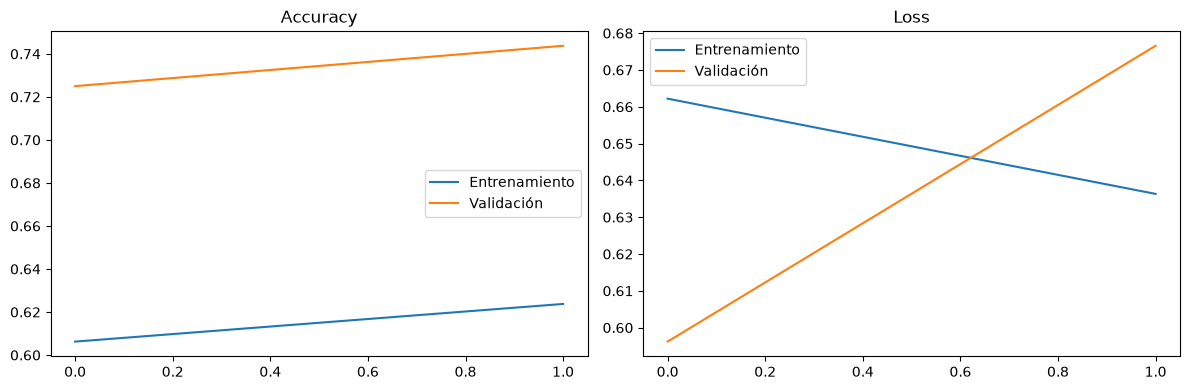

In [12]:
#Visualizar el entrenamiento
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validación")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")
plt.title("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
#Cargar el mejor modelo y evaluar
best_model = load_model("models/best_dogs_cats.keras")

tsdata.reset()
loss, accuracy = best_model.evaluate(tsdata)

print("Loss:", round(loss, 4))
print("Accuracy:", round(accuracy, 4))

623/623 ━━━━━━━━━━━━━━━━━━━━ 153s 239ms/step - accuracy: 0.5274 - loss: 0.7083
Loss: 0.7083
Accuracy: 0.5274


623/623 ━━━━━━━━━━━━━━━━━━━━ 146s 232ms/step
              precision    recall  f1-score   support

         cat       0.52      0.74      0.61      2500
         dog       0.54      0.31      0.40      2481

    accuracy                           0.53      4981
   macro avg       0.53      0.53      0.50      4981
weighted avg       0.53      0.53      0.50      4981



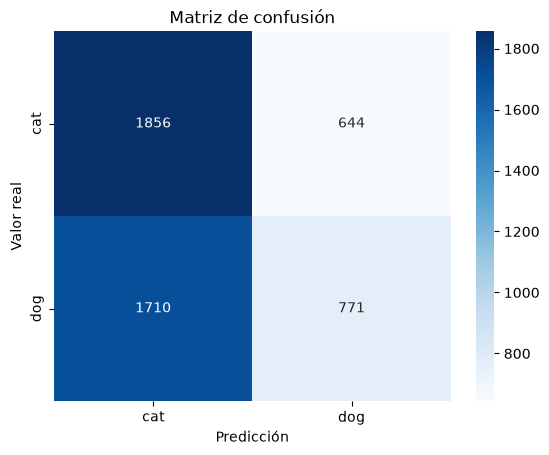

In [14]:
#Predicciones y matriz de confusión
tsdata.reset()

y_prob = best_model.predict(tsdata)
y_pred = np.argmax(y_prob, axis=1)
y_true = tsdata.classes

labels = list(tsdata.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=labels))

cm = confusion_matrix(y_true, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión")
plt.show()

## Conclusiones

En este proyecto hemos creado una red neuronal con EfficientNetB0 para clasificar imágenes de perros y gatos.

Hemos preparado las imágenes mediante generadores, entrenado el modelo y utilizado ModelCheckpoint y EarlyStopping para guardar la mejor versión y controlar el entrenamiento.

Finalmente, hemos evaluado el modelo con imágenes de test y analizado sus resultados mediante accuracy, el informe de clasificación y la matriz de confusión.

In [16]:
#Guardar el modelo
best_model.save("models/dogs_cats_efficientnetb0.keras")

print("Modelo guardado correctamente.")  

Modelo guardado correctamente.
